In [7]:

import numpy as np
import soundfile as sf
from pathlib import Path
import os
import matplotlib.pyplot as plt
import librosa as ls

In [2]:
p = 8

In [3]:
# Définition des chemins selon l'arborescence officielle de ParaSpeech

fichier = Path.cwd()
RACINE = fichier.parents[0]
DOSSIER_RAW = RACINE/"data"/"raw"
FICHIER_AUDIO = RACINE/"data"/"processed"/"audio"/"extrait"/"V002.wav"
FICHIER_REGISTRE = RACINE/"data"/"processed"/"videos.csv"

In [4]:
import os

chemin = "/home/romain/Bureau/AMA_PIIA/ParaSpeech_Africa/paraspeech/data/processed/audio/extrait/V002.wav"
print("Le fichier existe-t-il ?", os.path.exists(chemin))


Le fichier existe-t-il ? True


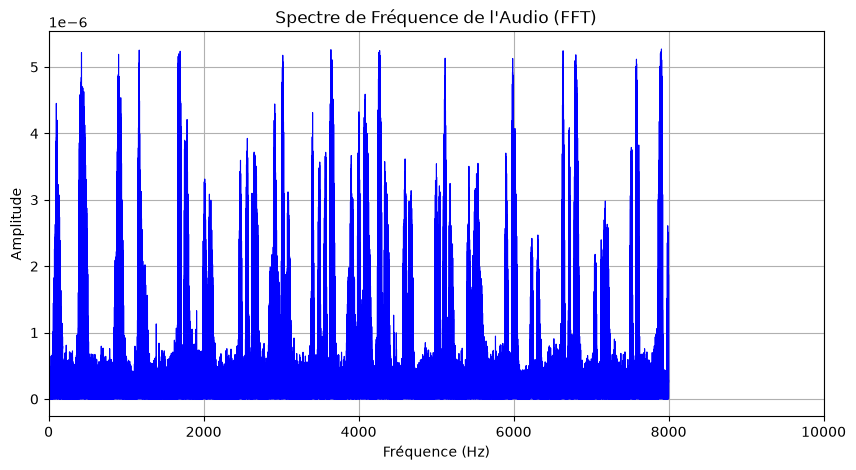

In [5]:
x , fs = sf.read(FICHIER_AUDIO)

N = len(x)
duree = N /fs # duree totale d'échantillonage 
fft_signal = np.fft.fft(x)
frequence = np.fft.fftfreq(N, 1/fs)[:N //2]
amplitudes = (2.0/N)*(np.abs(fft_signal[:N //2]))
# amplitude = np.max(np.abs(x))


# 3. Création du graphique
plt.figure(figsize=(10, 5))
plt.plot(frequence, amplitudes, color="blue", linewidth=0.8)

# Configuration des axes
plt.title("Spectre de Fréquence de l'Audio (FFT)")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

# Optionnel : Limiter l'affichage aux fréquences audibles humaines (0 à 20 000 Hz)
plt.xlim(0, 10000)

# Affichage du graphique
plt.show()

Fréquence d'échantillonnage : 16000 Hz
Durée totale du fichier : 47.32 secondes
Nombre total d'échantillons : 757156


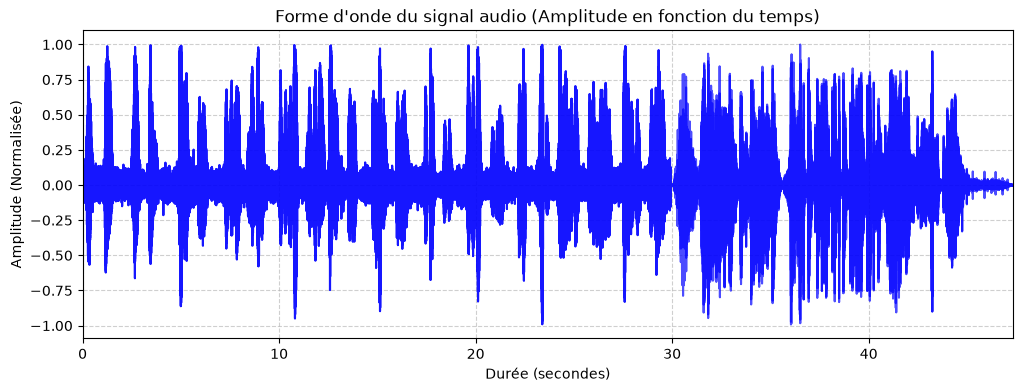

In [6]:
signal , fs = sf.read(FICHIER_AUDIO)

N = len(signal)
duree = N /fs # duree totale d'échantillonage 
# Crée un tableau de points allant de 0 à la durée totale, répartis équitablement
temps = np.linspace(0, duree, num=len(signal))

print(f"Fréquence d'échantillonnage : {fs} Hz")
print(f"Durée totale du fichier : {duree:.2f} secondes") 
print(f"Nombre total d'échantillons : {len(signal)}")

# 3. Visualisation graphique
plt.figure(figsize=(12, 4))
plt.plot(temps, signal, color="blue", alpha=0.7)

# Habillage du graphique
plt.title("Forme d'onde du signal audio (Amplitude en fonction du temps)")
plt.xlabel("Durée (secondes)")
plt.ylabel("Amplitude (Normalisée)")
plt.xlim(0, duree)
plt.grid(True, linestyle="--", alpha=0.6)


In [ ]:


# 1. Chargement avec la fréquence d'origine (sr=None)
signal, fr = ls.load(FICHIER_AUDIO, sr=None)

# 2. Création d'un tableau de temps pour chaque point du signal
temps = np.arange(len(signal)) / fr

# 3. Affichage du graphique
plt.figure(figsize=(14, 7))
plt.plot(temps, signal, linewidth=0.5)  # linewidth=0.5 rend l'onde plus nette
plt.title("Amplitude du signal audio en fonction du temps")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
